# Assignment: 1D linear Kalman filter for the distance to a wall

**Goal.** Estimate the distance $d$ from the robot to the wall in front of it by fusing

* the **prediction model** from Assignment 2, scenario 1 (wheel odometry in 1D, from David's solution): $\bar p_k = p_{k-1} + \Delta t\,v_k$ with $v = R\,\frac{\omega_A+\omega_B}{2}$ and $\mathbf Q=\mathbf B\sigma_v^2\mathbf B^\mathsf T$, $\sigma_v$ measured at constant voltage;
* the **measurement**: the front distance sensor.

The template (`robot.h`) defines `Meas2State = -1/R_WHEEL`, so the state is the **wheel angle relative to the wall**, $x=-d/R_\text{wheel}$ [rad]: driving forward increases $x$ towards 0 at the wall. David's model $p_k=p_{k-1}+\Delta t\,v_k$ is the same model written in rad ($p=R\,x$), so $\sigma_v$ is simply divided by $R_\text{wheel}$:

$$x=-\tfrac{d}{R_\text{wheel}},\quad u=\tfrac{\omega_A+\omega_B}{2},\quad \mathbf F=1,\ \mathbf B=\Delta t,\ \mathbf Q=\big(\Delta t\,\tfrac{\sigma_v}{R_\text{wheel}}\big)^2,\quad \mathbf H=-R_\text{wheel},\ R=\sigma_d^2$$

> **What is real and what is simulated.** $\sigma_v$ comes from the Assignment 2 recording R4. $\sigma_d$ comes from a stationary part of one of your recordings. The wall approach in section 3 is *simulated* with those noise values; section 5 replays the same filter on a real wall-approach recording as soon as `wall_approach.csv` exists.

## 1. Setup and settings

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import norm, chi2
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

R_WHEEL, DT = 0.0325, 0.010           # wheel radius [m], sample time [s]   (mecotron.h)

# ---- settings you may have to change -------------------------------------------------------
A2_DATA   = Path(r'C:\Users\User\Desktop\Mobile Robotics Assignment 2')   # R1-R5 logs of Assignment 2
R4_FILE   = 'R4_straight_fwd700mm_right190mm_turnR15deg.csv'
QRC       = Path(r'C:\Users\User\QRCrecords')
# Channels written by the TEMPLATE robot.cpp (writeValue): 0 uA, 1 uB, 2 posA, 3 posB, 4 spA, 5 spB, 6 xref, 7 front distance,
#                                                          8 xhat (a priori), 9 xhat (a posteriori), 10 innovation
CH_VA, CH_VB, CH_WA, CH_WB, CH_FRONT, CH_XHAT = 'ValueIn0', 'ValueIn1', 'ValueIn4', 'ValueIn5', 'ValueIn7', 'ValueIn9'
STILL_NEW = 'sensor_still.csv'                    # NEW recording (test 1): robot standing still, template robot.cpp
# Fallback until test 1 is done: an older recording (different robot.cpp). ValueIn9 is the live distance channel there
# (stable at 0.35 m when still, drop-outs at 24.78 m); this is inferred from the data, not from a source file.
STILL_OLD, CH_FRONT_OLD, CH_VA_OLD, CH_VB_OLD = 'log_gpio_23-10-2026_17-14-58.csv', 'ValueIn9', 'ValueIn0', 'ValueIn1'
WALL_FILE = 'wall_approach.csv'                   # NEW recording (test 3), template robot.cpp
# ---------------------------------------------------------------------------------------------

def read_qrc(path):
    df = pd.read_csv(path, skiprows=1); df.columns = df.columns.str.strip()
    return df.apply(pd.to_numeric, errors='coerce')

## 2. Model parameters

### 2.1 Prediction model: $\sigma_v$ from Assignment 2 (R4)
Same procedure as scenario 1 of Assignment 2: the spread of the wheel speed at **constant voltage** (steady 6 V parts of R4, each window minus its own mean), pooled over both wheels. Then $\mathbf Q=\mathbf B\,\sigma_v^2\,\mathbf B^\mathsf T=\Delta t^2\sigma_v^2$.

In [2]:
COLS = ['VA','VB','wA','wB','pA','pB','ax','ay','az','gx','gy','gz']           # column order of the Assignment 2 logs
R4 = pd.read_csv(A2_DATA / R4_FILE, header=1); R4.columns = ['Time'] + COLS
R4['t'] = (R4.Time - R4.Time.iloc[0]) / 1000

def pooled_std(df, col, windows):
    dev = [df[(df.t >= a) & (df.t < b)][col] - df[(df.t >= a) & (df.t < b)][col].mean() for a, b in windows]
    return np.concatenate(dev).std()

STEADY = [(31.9, 32.45), (33.0, 33.6)]                      # constant 6 V, rolling straight (as in Assignment 2)
sig_wA, sig_wB = pooled_std(R4, 'wA', STEADY), pooled_std(R4, 'wB', STEADY)
SIGMA_V = R_WHEEL * np.sqrt(sig_wA**2 + sig_wB**2) / 2      # std of the mean forward speed [m/s]

SIGMA_OMEGA = SIGMA_V / R_WHEEL                             # same noise expressed as mean wheel speed [rad/s]
F = 1.0
B = DT                                                      # applied to v = (wA + wB)/2 [rad/s]; forward increases x = -d/R_WHEEL
Q = (B * SIGMA_OMEGA) ** 2
print(f'sigma_wA = {sig_wA:.3f}, sigma_wB = {sig_wB:.3f} rad/s  ->  sigma_v = {SIGMA_V*1e3:.2f} mm/s = {SIGMA_OMEGA:.3f} rad/s')
print(f'F = {F}, B = {B}, Q = {Q:.3e} rad^2 per step')

sigma_wA = 0.237, sigma_wB = 0.276 rad/s  ->  sigma_v = 5.90 mm/s = 0.182 rad/s
F = 1.0, B = 0.01, Q = 3.300e-06 rad^2 per step


### 2.2 Measurement model: $H$ and $R$ from the stationary sensor
$z=d=-R_\text{wheel}\,x$, so $\mathbf H=-R_\text{wheel}$. $R=\sigma_d^2$ [m²] is the variance of the front sensor while the robot stands still.

sensor_still.csv not found, falling back to log_gpio_23-10-2026_17-14-58.csv (channel ValueIn9)
1195 stationary samples (11.9 s): mean 0.346 m, sigma_d = 21.8 mm  ->  R = 4.751e-04 m^2
largest value in the whole file: 24.78 m  (values like this are sensor drop-outs)


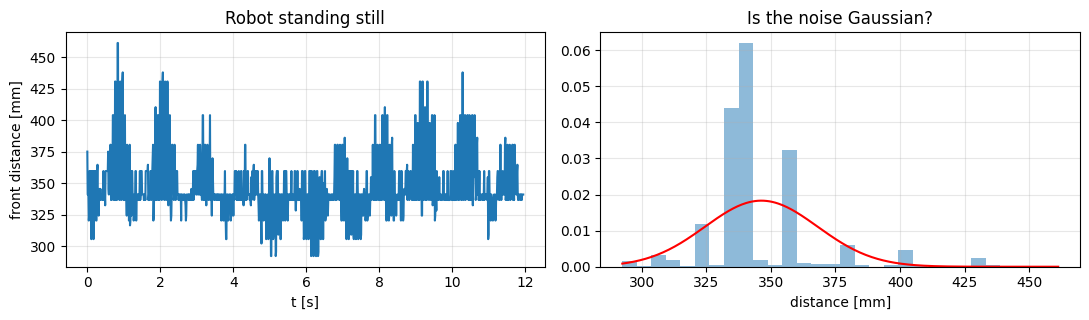

In [3]:
if (QRC / STILL_NEW).exists():
    raw = read_qrc(QRC / STILL_NEW); ch = CH_FRONT; print('using', STILL_NEW)
else:
    raw = read_qrc(QRC / STILL_OLD); ch = CH_FRONT_OLD; print(f'{STILL_NEW} not found, falling back to {STILL_OLD} (channel {ch})')
t   = ((raw.Time - raw.Time.iloc[0]) / 1000).values
dist = raw[ch].values
vcols = [CH_VA_OLD, CH_VB_OLD] if ch == CH_FRONT_OLD else [CH_VA, CH_VB]
moving = (raw[vcols] != 0).any(axis=1).values
still = (t < t[moving][0] - 0.2) if moving.any() else np.ones(len(t), bool)
d_still = dist[still]
H = -R_WHEEL                                                # z = d = H x
SIGMA_D = d_still.std(); R = SIGMA_D**2
print(f'{still.sum()} stationary samples ({t[still][-1]:.1f} s): mean {d_still.mean():.3f} m, sigma_d = {SIGMA_D*1e3:.1f} mm  ->  R = {R:.3e} m^2')
print(f'largest value in the whole file: {np.nanmax(dist):.2f} m  (values like this are sensor drop-outs)')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(t[still], 1e3*d_still); ax[0].set(xlabel='t [s]', ylabel='front distance [mm]', title='Robot standing still')
xs = np.linspace(d_still.min(), d_still.max(), 300)
ax[1].hist(1e3*d_still, bins=30, density=True, alpha=.5); ax[1].plot(1e3*xs, norm.pdf(xs, d_still.mean(), SIGMA_D)/1e3, 'r')
ax[1].set(xlabel='distance [mm]', title='Is the noise Gaussian?'); plt.tight_layout(); plt.show()

## 3. The filter and a simulated wall approach
Order as in `robot.cpp`: **correction** with the new measurement, then **prediction** to the next sample. An optional **gate**, identical to `CorrectionUpdate` in the firmware, skips the update for readings outside the sensor range 0.04–0.35 m (drop-outs read 24.78 m) and for innovations above 3σ ($\nu^2/S>9$). If more than 20 samples in a row (0.2 s) fail the 3σ test, the measurement is accepted again and $P$ is reset to $P_0$ first: then the *estimate* is wrong, not the sensor (e.g. a wrong initial guess), and a pure 3σ gate would lock the filter out forever. The counter starts at 0 for every run (`ResetGate()`).

The simulation drives from 0.45 m to about 0.18 m (still, accelerate to 4 rad/s, cruise, brake), with the measured sensor noise, 1.5 % drop-outs reading 24.78 m, the measured wheel-speed noise, and a **5 % wheel-speed scale error** that the filter does not know about. The filter starts from a wrong guess (0.37 m) with $P_0 = 9.5$ rad² $\approx(0.10\,\text{m}/R_\text{wheel})^2$, the firmware value.

In [ ]:
def lkf(z, w_mean, Q, R, x0, P0, gate=None):
    # state x = -d/R_WHEEL [rad]; w_mean = (wA + wB)/2 [rad/s]
    n = len(z); o = {k: np.zeros(n) for k in ['x', 'P', 'xb', 'Pb', 'nu', 'S', 'K']}; o['skip'] = np.zeros(n, bool)
    x, P, rejected = x0, P0, 0                                 # rejected = 0: ResetGate()
    for k in range(n):
        o['xb'][k], o['Pb'][k] = x, P
        nu = z[k] - H * x; S = H * P * H + R
        accept = True
        if gate is not None:                                   # same logic as CorrectionUpdate in the C++
            if not (D_MIN <= z[k] <= D_MAX):
                accept = False                                 # outside the sensor range (incl. drop-outs)
            elif nu**2 > gate * S:
                rejected += 1
                accept = rejected > MAX_REJECT                 # persistent: the estimate is wrong, re-sync
                if accept:
                    P = P0_STATE; S = H * P * H + R            # re-sync: widen P first, as in the firmware
            if accept:
                rejected = 0
        if not accept:
            K = 0.0; o['skip'][k] = True
        else:
            K = P * H / S
        x = x + K * nu; P = (1 - K * H) * P
        o['x'][k], o['P'][k], o['nu'][k], o['S'][k], o['K'][k] = x, P, nu, S, K
        x = F * x + B * w_mean[k]; P = F * P * F + Q                      # prediction (v = mean wheel speed)
    return o

GATE, D0_GUESS, SIG_D0, W_CRUISE = 9.0, 0.37, 0.10, 4.0
D_MIN, D_MAX, MAX_REJECT = 0.04, 0.35, 20                                                 # valid sensor range [m]; re-sync after 20 rejections (0.2 s)
P0_STATE = 9.5                                                             # [rad^2] = P0_STATE in state_estimator.h, ~(SIG_D0 / R_WHEEL)^2 = 10 cm
X0, P0 = D0_GUESS / -R_WHEEL, P0_STATE                                     # Meas2State and initial uncertainty
SIG_W_ENC = SIGMA_OMEGA                                                    # wheel-speed noise [rad/s] from section 2.1

def simulate(seed, d0=0.45, T=5.0, eps=0.05, p_drop=0.015):
    rng = np.random.default_rng(seed); n = int(round(T/DT)) + 1; tt = np.arange(n) * DT
    w_true = np.interp(tt, [0, .5, .9, 2.6, 3.0, T], [0, 0, W_CRUISE, W_CRUISE, 0, 0])
    d_true = d0 - R_WHEEL * np.concatenate([[0], np.cumsum(0.5 * (w_true[1:] + w_true[:-1]) * DT)])
    w_meas = (1 + eps) * w_true + rng.normal(0, SIG_W_ENC, n)
    z = d_true + rng.normal(0, SIGMA_D, n); z[rng.random(n) < p_drop] = 24.78
    return dict(t=tt, d=d_true, w=w_meas, z=z)

sim = simulate(3); tt, d_true, z, wm = sim['t'], sim['d'], sim['z'], sim['w']
f_plain, f_gate = lkf(z, wm, Q, R, X0, P0), lkf(z, wm, Q, R, X0, P0, gate=GATE)
d_pred = H * (X0 + B * np.concatenate([[0], np.cumsum(wm[:-1])]))        # prediction only, in metres

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
ok = z < 1
ax[0].plot(tt[ok], 1e3*z[ok], '.', ms=2.5, color='0.65', label='sensor (drop-outs not shown)')
ax[0].plot(tt, 1e3*d_pred, '--', color='tab:orange', label='prediction only')
ax[0].plot(tt, 1e3*d_true, 'k', lw=1.2, label='true'); ax[0].plot(tt, 1e3*H*f_gate['x'], 'tab:blue', lw=1.8, label='Kalman filter (gate)')
sd = R_WHEEL*np.sqrt(f_gate['P']); ax[0].fill_between(tt, 1e3*(H*f_gate['x']-3*sd), 1e3*(H*f_gate['x']+3*sd), color='tab:blue', alpha=.2, label=r'$\pm3\sigma$ from P')
ax[0].set(ylim=(80, 520), ylabel='distance [mm]', title='Simulated wall approach'); ax[0].legend(ncol=3, fontsize=8)
ax[1].plot(tt, 1e3*(H*f_gate['x']-d_true), label='filter'); ax[1].plot(tt, 1e3*(d_pred-d_true), '--', color='tab:orange', label='prediction only')
ax[1].set(ylim=(-90, 90), xlabel='t [s]', ylabel='error [mm]'); ax[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

### 3.1 Why the gate is needed, Gaussian picture, and consistency

In [ ]:
k = int(np.flatnonzero((z > 1) & (tt > 1.0))[0])
print(f'drop-out at t = {tt[k]:.2f} s: sensor reads {z[k]:.2f} m; innovation = {abs(f_plain["nu"][k]/np.sqrt(f_plain["S"][k])):.0f} sigma')
print(f'estimate jump without gate: {1e3*R_WHEEL*abs(f_plain["x"][k]-f_plain["xb"][k]):.0f} mm, with gate: {1e3*R_WHEEL*abs(f_gate["x"][k]-f_gate["xb"][k]):.1f} mm')

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, kk, ttl in zip(ax, [0, 1, 450], ['t = 0: prior uncertain, measurement dominates', 't = 0.01 s', 't = 4.5 s: steady state, model dominates']):
    o = f_gate; m_pr, s_pr, m_po, s_po = H*o['xb'][kk], R_WHEEL*np.sqrt(o['Pb'][kk]), H*o['x'][kk], R_WHEEL*np.sqrt(o['P'][kk])
    xs = np.linspace(min(m_pr-4*s_pr, z[kk]-4*SIGMA_D), max(m_pr+4*s_pr, z[kk]+4*SIGMA_D), 600)
    a.plot(1e3*xs, norm.pdf(xs, m_pr, s_pr)/1e3, 'tab:orange', label='prior'); a.plot(1e3*xs, norm.pdf(xs, z[kk], SIGMA_D)/1e3, 'tab:green', label='measurement')
    a.plot(1e3*xs, norm.pdf(xs, m_po, s_po)/1e3, 'tab:blue', lw=2, label='posterior'); a.axvline(1e3*d_true[kk], color='k', ls=':')
    a.set_title(ttl + f'\nK = {o["K"][kk]:.3f}', fontsize=9); a.set_xlabel('distance [mm]'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# consistency: normalised innovation squared over many runs (drop-outs excluded), expected mean 1
nis = []
for s in range(40):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], Q, R, X0, P0, gate=GATE); keep = ~o['skip'] & (sm['t'] > 1)
    nis.append((o['nu']**2 / o['S'])[keep])
nis = np.concatenate(nis)
print(f'mean NIS = {nis.mean():.2f} (ideal 1);  share above the 95 % chi2 limit = {100*(nis > chi2.ppf(.95, 1)).mean():.1f} % (ideal 5 %)')

# wrong initial guess (ValueOut1 left at 0): a pure 3-sigma gate never accepts a measurement again
def plain_3sigma_gate(z, w, x0):
    x, P = x0, P0
    for k in range(len(z)):
        nu = z[k] - H * x; S = H * P * H + R
        if nu**2 <= GATE * S: K = P * H / S; x += K * nu; P = (1 - K * H) * P
        x += B * w[k]; P += Q
    return H * x
bad = 0.0 / -R_WHEEL + 1e-9
print(f'start guess 0 m, true 0.45 m -> final error: pure 3-sigma gate {1e3*(plain_3sigma_gate(z, wm, bad) - d_true[-1]):+.0f} mm, '
      f'gate with re-sync {1e3*(H*lkf(z, wm, Q, R, bad, P0, gate=GATE)["x"][-1] - d_true[-1]):+.1f} mm')

## 4. Tuning check and comparison
RMSE after the start-up transient ($t>1$ s) over 100 simulated runs, and the sensitivity to scaling $Q$ and $R$.

In [ ]:
res = {k: [] for k in ['sensor (drop-outs removed)', 'prediction only', 'LKF (no gate)', 'LKF + gate']}
for s in range(100):
    sm = simulate(s); m = sm['t'] > 1; ok = sm['z'] < 1; e = lambda est: np.sqrt(np.mean((est - sm['d'])[m]**2))
    res['sensor (drop-outs removed)'].append(np.sqrt(np.mean((sm['z'] - sm['d'])[m & ok]**2)))
    res['prediction only'].append(e(H * (X0 + B * np.concatenate([[0], np.cumsum(sm['w'][:-1])]))))
    res['LKF (no gate)'].append(e(H * lkf(sm['z'], sm['w'], Q, R, X0, P0)['x'])); res['LKF + gate'].append(e(H * lkf(sm['z'], sm['w'], Q, R, X0, P0, gate=GATE)['x']))
print(pd.DataFrame({k: [1e3*np.median(v), 1e3*np.percentile(v, 95)] for k, v in res.items()}, index=['median RMSE [mm]', '95th pct [mm]']).T.round(1).to_string())

def rmse_scaled(s, qm, rm):
    sm = simulate(s); o = lkf(sm['z'], sm['w'], Q*qm, R*rm, X0, P0, gate=GATE)
    return np.sqrt(np.mean((H * o['x'] - sm['d'])[sm['t'] > 1]**2))
sc = np.logspace(-2, 3, 11); grid = np.zeros((len(sc), len(sc)))
for i, qm in enumerate(sc):
    for j, rm in enumerate(sc):
        grid[i, j] = np.mean([rmse_scaled(s, qm, rm) for s in range(8)])
plt.figure(figsize=(6, 4.8)); plt.imshow(1e3*grid, origin='lower', extent=[-2, 3, -2, 3], cmap='viridis_r', aspect='auto'); plt.plot(0, 0, 'r*', ms=14, label='Q, R from data')
plt.colorbar(label='RMSE [mm]'); plt.xlabel('log10 (R scale)'); plt.ylabel('log10 (Q scale)'); plt.legend(); plt.grid(False); plt.show()
i, j = np.unravel_index(grid.argmin(), grid.shape)
print(f'best on grid: Q x {sc[i]:.2g}, R x {sc[j]:.2g} -> {1e3*grid[i,j]:.1f} mm;  data values (x1, x1): {1e3*grid[5,5]:.1f} mm')

## 5. Replay on the real wall-approach recording
Skipped until `wall_approach.csv` exists (test 3). Channels are those of the template: wheel speeds `ValueIn4/5`, front distance `ValueIn7`, on-board a-posteriori estimate `ValueIn9` [rad]. Set `D_START_RULER` (the value you entered in `ValueOut1`) and `D_END_RULER` below.

In [7]:
D_START_RULER, D_END_RULER = None, None            # [m] measured with the ruler at the start / after the stop
wp = next((p for p in [Path(WALL_FILE), QRC / WALL_FILE] if p.exists()), None)
if wp is None:
    print(f'{WALL_FILE} not found: no real wall-approach recording yet, step skipped.')
else:
    rw = read_qrc(wp); tw = ((rw.Time - rw.Time.iloc[0]) / 1000).values
    zw, ww = rw[CH_FRONT].values, ((rw[CH_WA] + rw[CH_WB]) / 2).values
    d_init = D_START_RULER if D_START_RULER else float(np.median(zw[:50]))
    o = lkf(zw, ww, Q, R, d_init / -R_WHEEL, P0, gate=GATE)
    plt.figure(figsize=(10, 3.8)); plt.plot(tw, zw, '.', ms=2, color='0.7', label='sensor'); plt.plot(tw, H * o['x'], label='LKF (offline replay)')
    if CH_XHAT in rw: plt.plot(tw, H * rw[CH_XHAT].values, '--', label='on-board estimate')
    plt.ylim(0, 0.6); plt.xlabel('t [s]'); plt.ylabel('distance [m]'); plt.legend(); plt.show()
    o['x'] = H * o['x']
    print(f'final estimate {o["x"][-1]*1e3:.0f} mm' + (f', ruler {D_END_RULER*1e3:.0f} mm, error {1e3*(o["x"][-1]-D_END_RULER):+.0f} mm' if D_END_RULER else ''))
    print(f'rejected by the gate: {o["skip"].sum()} of {len(zw)} samples')

wall_approach.csv not found: no real wall-approach recording yet, step skipped.


## 6. Consistency with the firmware
The firmware (`INTERNAL-StateEstimation_StateFeedback/`) is the reference. This cell reads the numbers from `state_estimator.h/.cpp` and checks that they equal the values used in this notebook. If it fails, either the data gave new values (update the firmware) or the firmware changed (update the notebook), in the same commit. `K`, `xref` and `_xhat(0)` are set in `robot.cpp` (see the README).

In [ ]:
import re
FW = Path('INTERNAL-StateEstimation_StateFeedback')
fw_src = (FW / 'state_estimator.h').read_text() + (FW / 'state_estimator.cpp').read_text()

def fw_value(name):
    # numeric value of 'NAME = <number>' in the firmware source
    m = re.search(rf'\b{name}\s*=\s*([-+0-9.eE]+)f?\s*;', fw_src)
    assert m, f'{name} not found in the firmware'
    return float(m.group(1))

check = pd.DataFrame({
    'firmware': [fw_value('Q_PROCESS'), fw_value('R_MEAS'), fw_value('P0_STATE'), fw_value('D_MIN'), fw_value('D_MAX'),
                 fw_value('GATE'), fw_value('MAX_REJECT')],
    'notebook': [Q, R, P0_STATE, D_MIN, D_MAX, GATE, MAX_REJECT],
}, index=['Q [rad^2]', 'R [m^2]', 'P0 [rad^2]', 'D_MIN [m]', 'D_MAX [m]', 'gate nu^2/S', 're-sync count'])
check['equal'] = np.isclose(check.firmware, check.notebook, rtol=1e-6, atol=0)
print(check.to_string())
assert re.search(r'H\s*=\s*\{\s*-R_WHEEL\s*\}', fw_src) and H == -R_WHEEL, 'H must be -R_WHEEL in both'
assert check['equal'].all(), 'notebook and firmware differ: update one of them (same commit)'
print('H = -R_WHEEL in both. Notebook and firmware match.')

**Limitations.** The wall approach in section 3 is simulated; unless `sensor_still.csv` exists, $R$ comes from an older recording whose front-distance channel is inferred from the data; $R$ is measured at one distance (0.35 m) although the sensor noise changes with distance; and the speed scale error is a bias that the white-noise $Q$ does not represent.